#### MPAS Skew-T Profile at a Point
- Nearest-cell vertical profile from isobaric diagnostic output (surface + standard pressure levels)
- Skew-T/log-p plot with wind barbs, using MetPy
- CAPE/CIN as reported directly by MPAS diagnostics

**Data**: SouthAmerica 240-48km variable-resolution tutorial run, `diag.*.nc` (standard-pressure-level diagnostics: `temperature_<p>hPa`, `dewpoint_<p>hPa`, `uzonal_<p>hPa`, `umeridional_<p>hPa`).

Ming Ge Nov. 2026

In [1]:
import numpy as np
import xarray as xr
from scipy.interpolate import griddata
import matplotlib.pyplot as plt
from metpy.plots import SkewT
from metpy.units import units

from mpas_utils import mpas_lonlat_deg

#### Load mesh and one diagnostic file

In [2]:
data_dir = '/glade/campaign/mmm/c3we/mingge/MPAS_PROJ/mpas_tutorial/240-48km_variable/'

ds_i = xr.open_dataset(data_dir + 'SouthAmerica.init.nc')
lonCell, latCell = mpas_lonlat_deg(ds_i['lonCell'].values, ds_i['latCell'].values)
points = np.column_stack([lonCell, latCell])

ds = xr.open_dataset(data_dir + 'diag.2014-09-10_00.00.00.nc').squeeze()

#### Nearest-cell profile at a station

In [3]:
lon_pt, lat_pt = -58.4, -34.6  # Buenos Aires, inside the SouthAmerica domain
levels_hpa = [925, 850, 700, 500, 250, 200, 100, 50]

def at_point(varname):
    return float(griddata(points, ds[varname].values, (lon_pt, lat_pt), method='nearest'))

# MPAS surface_pressure isn't in this diag stream; mslp is used as the surface-point
# pressure instead (a fair approximation away from steep terrain).
P = [at_point('mslp') / 100.0]
T = [at_point('t2m') - 273.15]
Td = [at_point('dewpoint_surface') - 273.15]
U = [at_point('uzonal_surface')]
V = [at_point('umeridional_surface')]

for lv in levels_hpa:
    P.append(lv)
    T.append(at_point(f'temperature_{lv}hPa') - 273.15)
    Td.append(at_point(f'dewpoint_{lv}hPa') - 273.15)
    U.append(at_point(f'uzonal_{lv}hPa'))
    V.append(at_point(f'umeridional_{lv}hPa'))

P, T, Td, U, V = (np.asarray(x) for x in (P, T, Td, U, V))
order = np.argsort(P)[::-1]  # surface (highest pressure) first
P, T, Td, U, V = P[order], T[order], Td[order], U[order], V[order]

P = P * units.hPa
T = T * units.degC
Td = Td * units.degC
U = U * units('m/s')
V = V * units('m/s')

#### Skew-T plot

CAPE: 31 J/kg,  CIN: 42 J/kg


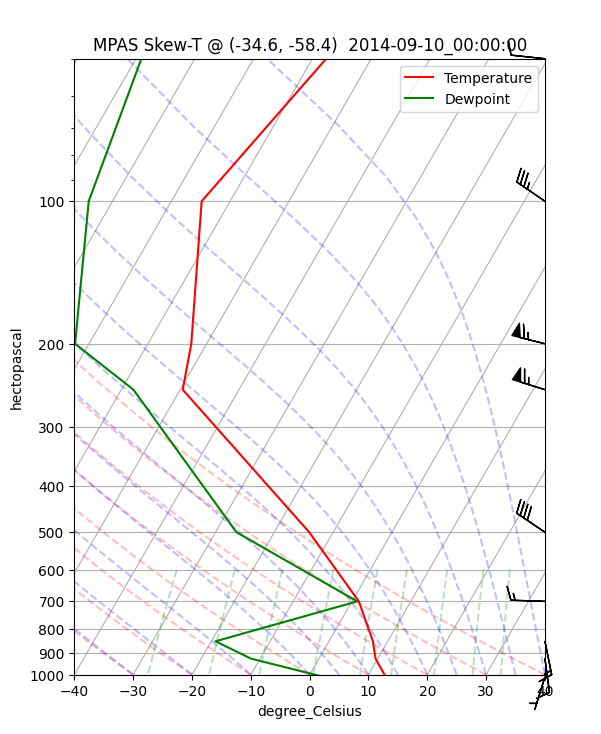

In [4]:
fig = plt.figure(figsize=(7, 8))
skew = SkewT(fig)
skew.plot(P, T, 'r', label='Temperature')
skew.plot(P, Td, 'g', label='Dewpoint')
skew.plot_barbs(P, U, V)
skew.ax.set_ylim(1000, 50)
skew.ax.set_xlim(-40, 40)
skew.plot_dry_adiabats(alpha=0.25)
skew.plot_moist_adiabats(alpha=0.25)
skew.plot_mixing_lines(alpha=0.25)
skew.ax.legend(loc='upper right')
skew.ax.set_title(f'MPAS Skew-T @ ({lat_pt}, {lon_pt})  '
                   + ds['xtime'].values.item().decode().strip())

print(f"CAPE: {at_point('cape'):.0f} J/kg,  CIN: {at_point('cin'):.0f} J/kg")